In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.distributional_pca import DistributionalPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))

    min_weights = weights.min()
    max_weights = weights.max()
    diff = max_weights - min_weights
    
    if diff == 0:
        alpha = weights
    else:
        alpha = 0.05 + 0.95 * (weights - min_weights) / diff

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    pc = ts[:,None] * eig_distr_pca[0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="Distributional PCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]

        if k == 0:
            plt.plot(pc[:,0], pc[:,1], c="orange", label="Lifted PCA", alpha=alpha[k])
        else:
            plt.plot(pc[:,0], pc[:,1], c="orange", alpha=alpha[k])

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

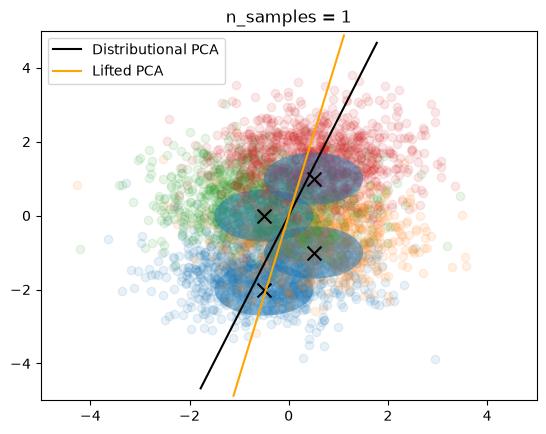

n=1 Lifted 1.1432716250419617 Distributional 1.1302955448627472


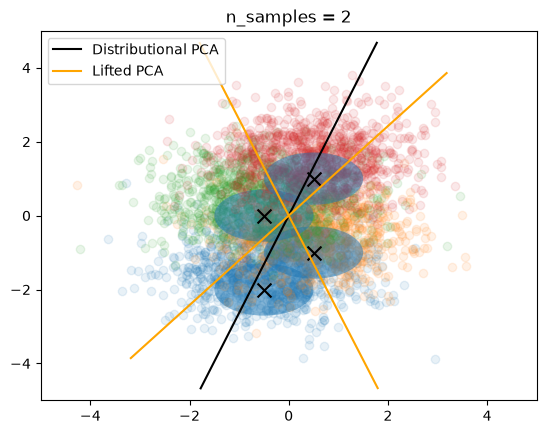

n=2 Lifted 0.5149590522050858 Distributional 1.1302955448627472


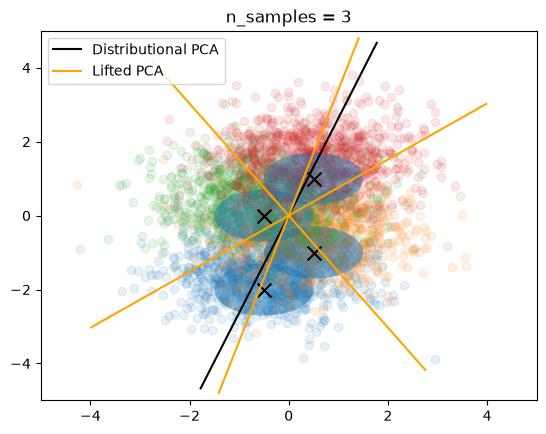

n=3 Lifted 0.3113250136375427 Distributional 1.1302955448627472


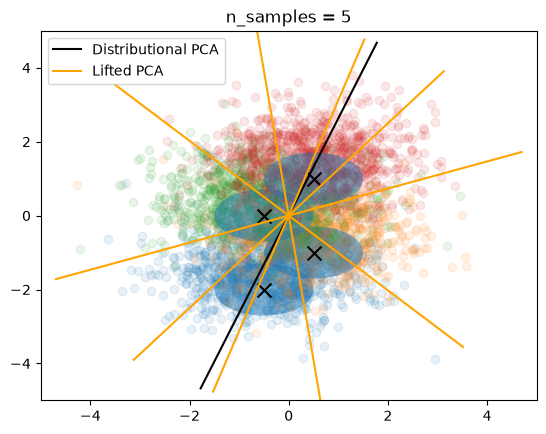

n=5 Lifted 0.16447589360177517 Distributional 1.1302955448627472


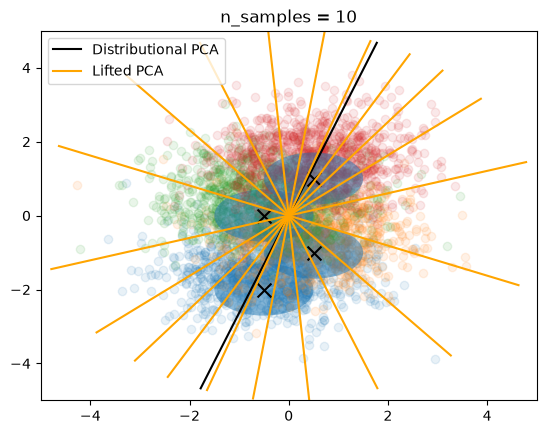

n=10 Lifted 0.09319055918604136 Distributional 1.1302955448627472


In [4]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

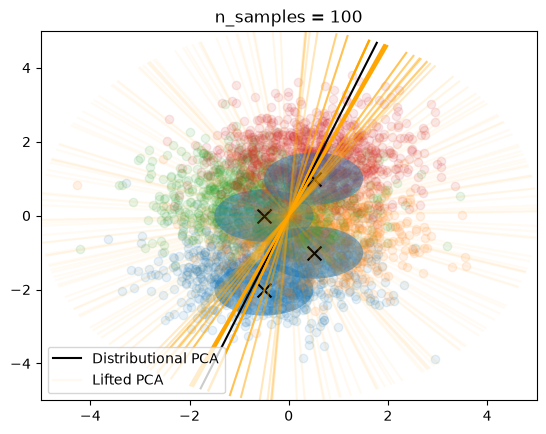

0.622767336666584


In [5]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [6]:
lifted_pca.weights_

tensor([0.0009, 0.0006, 0.0009, 0.0020, 0.0002, 0.0002, 0.0003, 0.0002, 0.0002,
        0.0940, 0.0002, 0.0008, 0.0004, 0.0005, 0.0002, 0.0004, 0.0003, 0.0227,
        0.0137, 0.0013, 0.0006, 0.0475, 0.0626, 0.0002, 0.0007, 0.0937, 0.0002,
        0.0443, 0.0016, 0.0017, 0.0041, 0.0004, 0.0002, 0.0266, 0.0003, 0.0002,
        0.0053, 0.0002, 0.0002, 0.0003, 0.0613, 0.0002, 0.0002, 0.0002, 0.0006,
        0.0002, 0.0007, 0.0002, 0.0004, 0.0002, 0.0016, 0.0003, 0.0018, 0.0002,
        0.0003, 0.0180, 0.0924, 0.0005, 0.0011, 0.0053, 0.0004, 0.0004, 0.0159,
        0.0004, 0.0037, 0.0951, 0.0003, 0.0139, 0.0004, 0.0372, 0.0940, 0.0073,
        0.0003, 0.0352, 0.0002, 0.0026, 0.0002, 0.0002, 0.0011, 0.0005, 0.0002,
        0.0002, 0.0269, 0.0002, 0.0004, 0.0022, 0.0007, 0.0003, 0.0008, 0.0024,
        0.0217, 0.0132, 0.0002, 0.0004, 0.0002, 0.0023, 0.0003, 0.0004, 0.0005,
        0.0010])

In [7]:
lifted_pca.weights_.max()

tensor(0.0951)

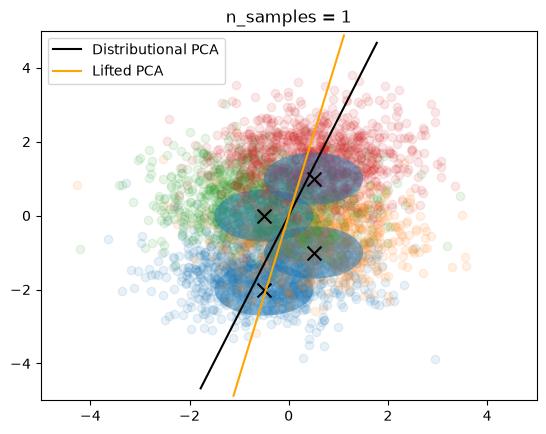

n=1 Lifted 1.1432716250419617 Distributional 1.1302955448627472
[1.]


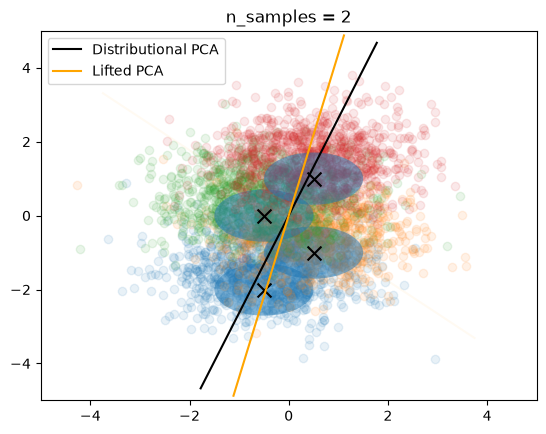

n=2 Lifted 1.1432716846466064 Distributional 1.1302955448627472
[1.000000e+00 7.581718e-17]


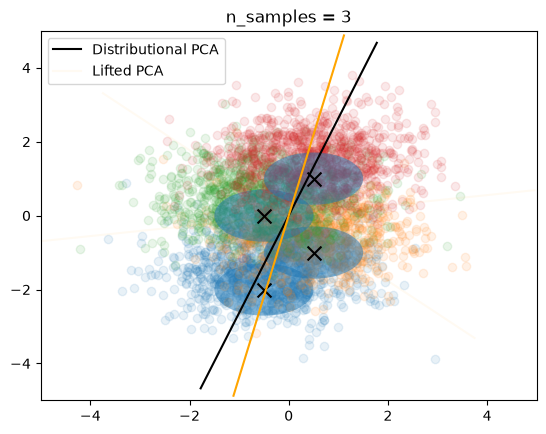

n=3 Lifted 1.1432716846466064 Distributional 1.1302955448627472
[1.7968576e-14 1.0000000e+00 1.2323434e-17]


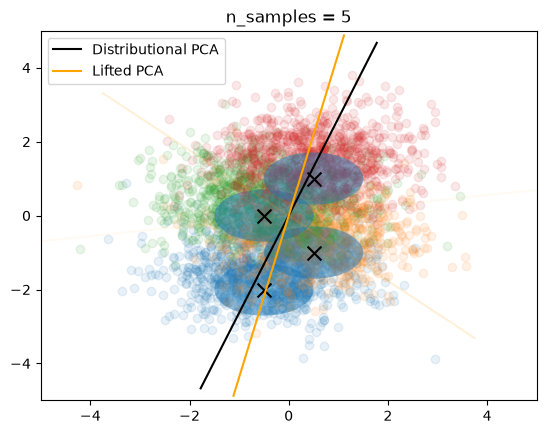

n=5 Lifted 1.1432716846466064 Distributional 1.1302955448627472
[1.0000000e+00 5.3880808e-17 1.8974392e-14 1.0851211e-17 6.3831849e-18]


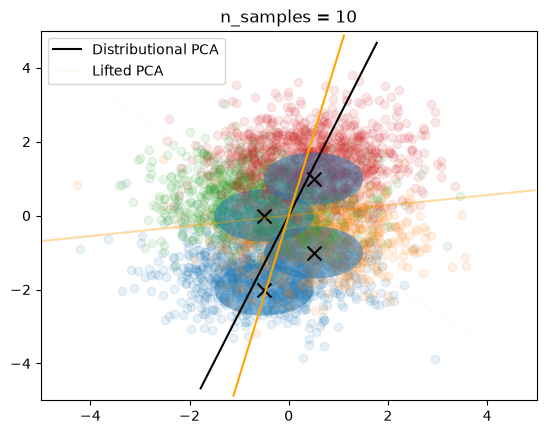

n=10 Lifted 1.1432716846466064 Distributional 1.1302955448627472
[6.3458739e-14 2.3510432e-17 6.4450647e-16 8.3652100e-16 9.1354879e-17
 1.8701758e-17 1.0000000e+00 3.2610878e-17 8.8248081e-17 6.3140255e-16]


In [8]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [9]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

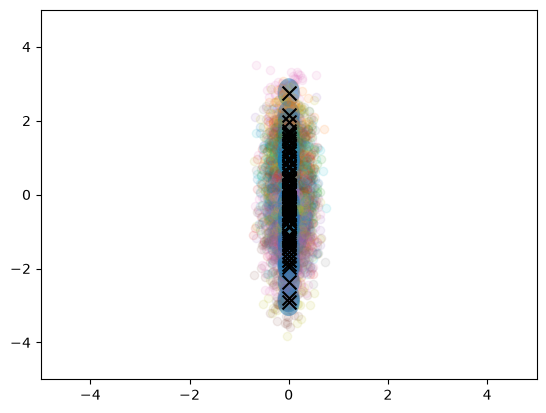

In [10]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

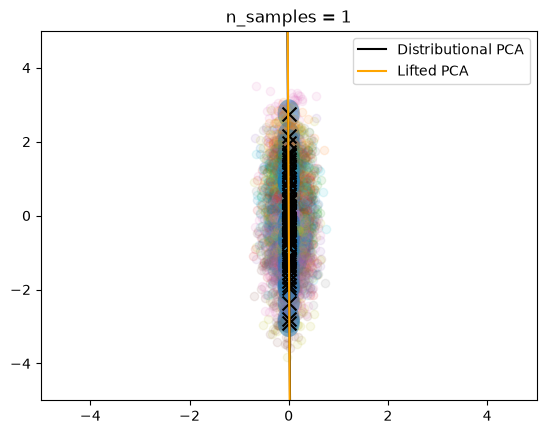

n=1 Lifted 0.050256724171340465 Distributional 0.05025491127744317


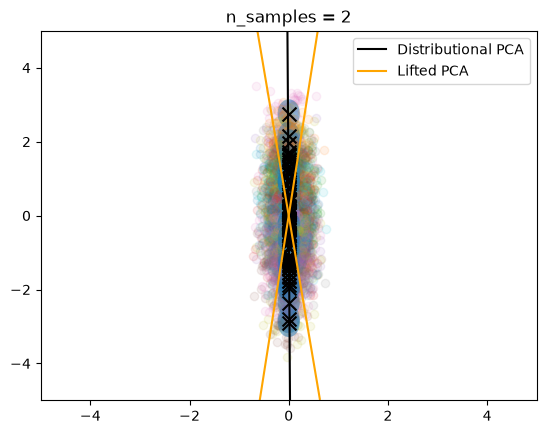

n=2 Lifted 0.029995954101905226 Distributional 0.05025491127744317


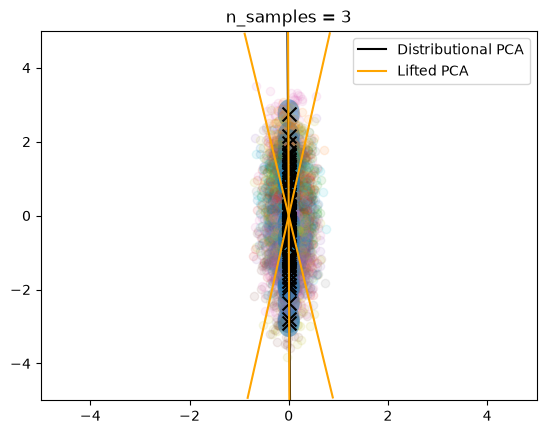

n=3 Lifted 0.02406398769468069 Distributional 0.05025491127744317


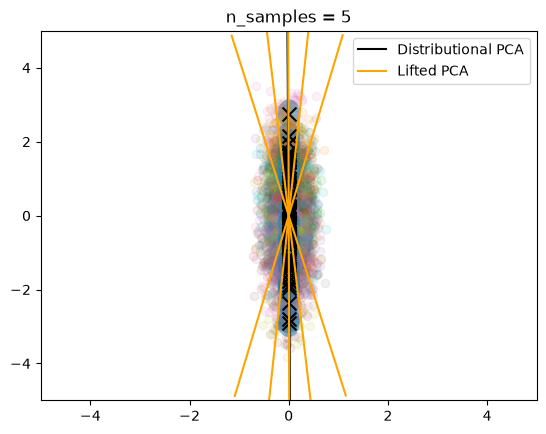

n=5 Lifted 0.020115074054338038 Distributional 0.05025491127744317


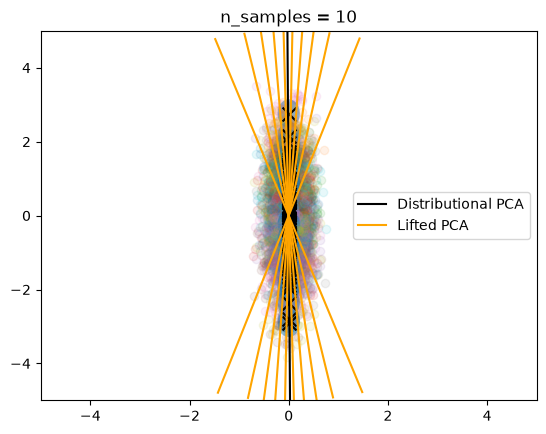

n=10 Lifted 0.017575143517460673 Distributional 0.05025491127744317


In [11]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

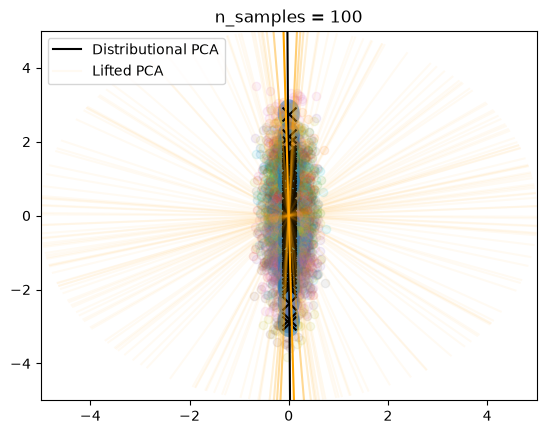

0.029696036912500858


In [12]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [13]:
lifted_pca.weights_

tensor([3.0082e-04, 4.2627e-04, 2.0206e-05, 3.0518e-04, 2.8829e-05, 1.5328e-05,
        2.7135e-05, 1.4908e-05, 1.6951e-01, 6.1466e-05, 1.0353e-04, 1.4002e-05,
        1.4582e-05, 8.2882e-05, 4.2945e-05, 1.4009e-05, 2.8224e-04, 2.2636e-05,
        1.4226e-03, 1.5829e-05, 2.1988e-03, 9.6194e-03, 6.0074e-04, 2.2090e-03,
        1.0150e-02, 1.4302e-05, 2.0886e-05, 2.6460e-02, 2.8831e-05, 1.2780e-01,
        4.5468e-05, 1.8934e-05, 1.4710e-05, 4.6043e-05, 3.5369e-02, 8.9445e-03,
        2.8170e-05, 7.5252e-04, 1.5140e-05, 1.4072e-05, 1.7127e-05, 3.5694e-05,
        2.8174e-05, 8.4121e-04, 2.1293e-05, 1.9853e-05, 1.3855e-05, 7.6875e-03,
        4.0343e-05, 4.4131e-05, 1.3765e-05, 1.7453e-05, 1.5243e-02, 1.4564e-04,
        3.7969e-05, 1.4829e-05, 3.9501e-03, 7.2592e-05, 1.4238e-05, 3.2197e-01,
        1.5328e-04, 2.1282e-02, 1.0226e-04, 5.1990e-05, 1.3844e-05, 1.8550e-05,
        1.3489e-03, 1.3889e-05, 3.6232e-05, 4.4440e-04, 1.7480e-05, 2.8401e-05,
        1.0749e-01, 2.3893e-05, 2.4994e-

In [14]:
lifted_pca.weights_.max()

tensor(0.3220)

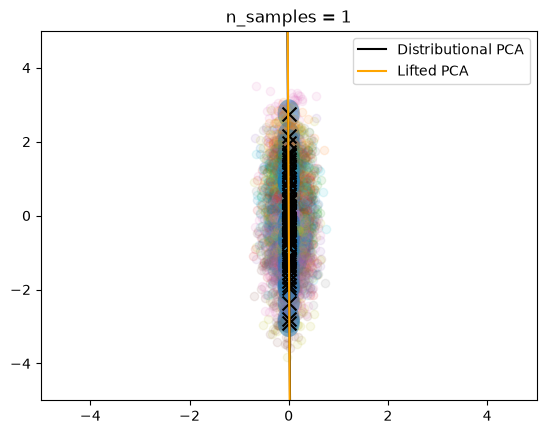

n=1 Lifted 0.050256724171340465 Distributional 0.05025491127744317
[1.]


KeyboardInterrupt: 

In [15]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [16]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

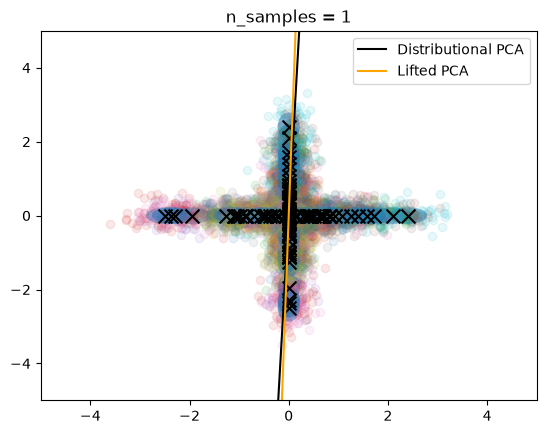

n=1 Lifted 0.6824975083209575 Distributional 0.6824935980699957


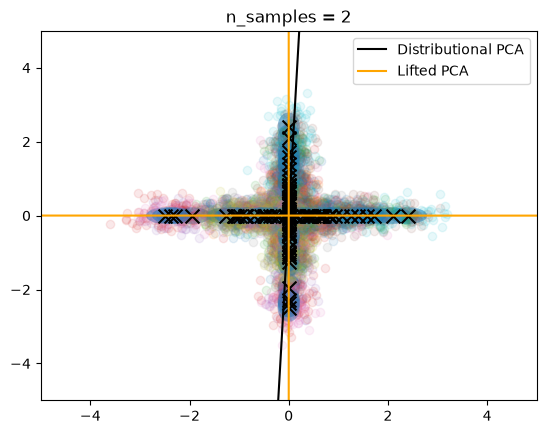

n=2 Lifted 0.4116404056362808 Distributional 0.6824935980699957


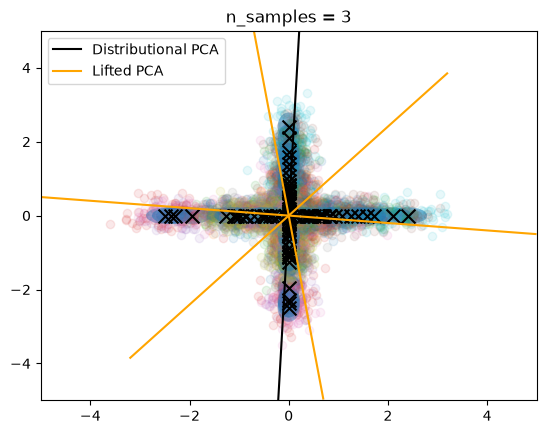

n=3 Lifted 0.39537076133303345 Distributional 0.6824935980699957


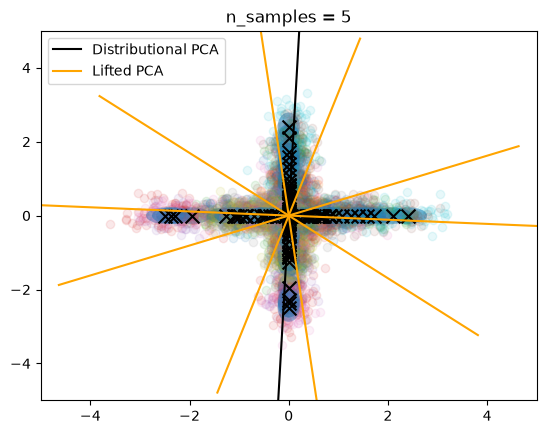

n=5 Lifted 0.36134020510595294 Distributional 0.6824935980699957


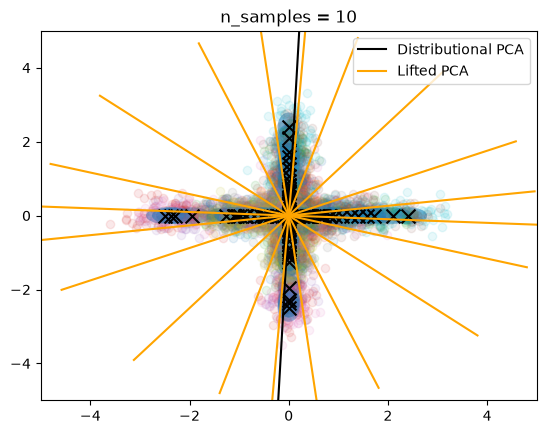

n=10 Lifted 0.34572547908639534 Distributional 0.6824935980699957


In [17]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

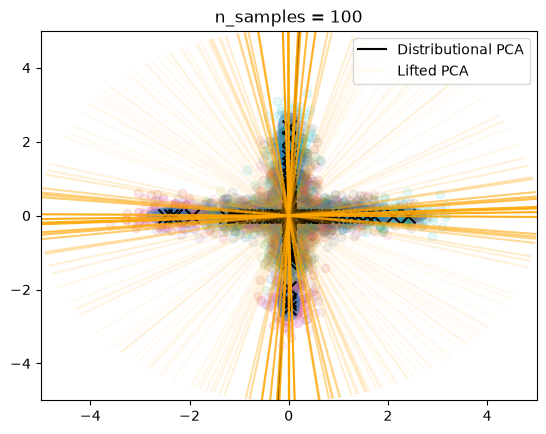

0.36431377769913525


In [18]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [19]:
lifted_pca.weights_

tensor([0.0008, 0.0051, 0.0009, 0.0418, 0.0009, 0.0009, 0.0058, 0.0008, 0.0008,
        0.0174, 0.0035, 0.0326, 0.0025, 0.0122, 0.0009, 0.0011, 0.0275, 0.0009,
        0.0010, 0.0147, 0.0461, 0.0251, 0.0013, 0.0013, 0.0040, 0.0008, 0.0021,
        0.0082, 0.0011, 0.0267, 0.0012, 0.0071, 0.0010, 0.0014, 0.0038, 0.0017,
        0.0028, 0.0032, 0.0173, 0.0054, 0.0282, 0.0015, 0.0008, 0.0274, 0.0037,
        0.0193, 0.0118, 0.0119, 0.0016, 0.0009, 0.0014, 0.0406, 0.0216, 0.0013,
        0.0041, 0.0008, 0.0012, 0.0008, 0.0238, 0.0301, 0.0010, 0.0065, 0.0026,
        0.0018, 0.0168, 0.0012, 0.0009, 0.0017, 0.0012, 0.0465, 0.0043, 0.0132,
        0.0010, 0.0010, 0.0064, 0.0044, 0.0396, 0.0352, 0.0011, 0.0009, 0.0426,
        0.0015, 0.0415, 0.0040, 0.0016, 0.0027, 0.0009, 0.0162, 0.0047, 0.0024,
        0.0008, 0.0010, 0.0061, 0.0008, 0.0464, 0.0025, 0.0275, 0.0409, 0.0012,
        0.0009])

In [20]:
lifted_pca.weights_.max()

tensor(0.0465)

In [21]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

KeyboardInterrupt: 